In [1]:
### Follow the code for disorder analysis Y SHO subband space ###

In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
from Minimal_Model_2D import *
import time

np.set_printoptions(threshold=sys.maxsize)


In [3]:
class Minimal_Model_Subband_Basis(twoD_Minimal_Model):

    def Ham(self, dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0):

        M = bmat([
           [self.H_same_spin(dis_mag, uncorr_var, lmbda, seed, kx, ky ), self.Del_array(phi) ],
           [self.Del_array(phi).conjugate().transpose(),-self.H_same_spin(dis_mag, uncorr_var, lmbda, seed, -kx, -ky).conjugate() ]
       ]) 

        return M
    
    def U_dag_ph(self, my=1):

        M = bmat([
            [ self.U_dag(my), None],
            [None, self.U_dag(my).conjugate()],
        ])

        return M
    
    '''
    def Ham_changed_basis(self,  dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0, my=1):

        S_dag = self.U_dag_ph(my)

        S = self.U_dag_ph(my).transpose().conjugate()

        H = self.Ham(dis_mag, uncorr_var, lmbda, seed, kx, ky,phi)

        return S_dag.dot(H).dot(S)
    '''
    def Ham_changed_basis(self,  dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0, my=1):

        S = self.U_num_ph(my)

        S_dag = S.conjugate().transpose()

        H = self.Ham(dis_mag, uncorr_var, lmbda, seed, kx, ky,phi)

        return S_dag.dot(H).dot(S)
    
    def Wvfn_overlap(self, V1, V2):

        ### returns overlap between wavefunction V1 and V2 ####

        V_ele_wse_product = np.multiply(np.conjugate(V1), V2)

        return np.sum(V_ele_wse_product) ### Reimann sum for 2D integration 

In [4]:

NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 4           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC


print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SC)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 1167  ### uncorrelated variance of disorder
LMBDA = np.linspace(0.00, 0.21, 51)
SEED = 58  ## seed for the disorder

first_sub_wt_p = np.empty(LMBDA.shape[0])
second_sub_wt_p = np.empty(LMBDA.shape[0])

Mod = Minimal_Model_Subband_Basis(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)

for i in range(LMBDA.shape[0]):
    print('i =', i)

    H = Mod.Ham_changed_basis(uncorr_var= UNCORR_VAR, lmbda=LMBDA[i], seed=SEED, my=MY, phi= PHI)

    E,V = eigsh(H, k=K_NUM, sigma=0)

    sorted_index = np.argsort(E)

    E_sorted = E[sorted_index]

    V_sorted = V[:,sorted_index]

    #print(E_sorted)

    Wv_gs = V[:,K_NUM//2].reshape(2,MY,NTOT)

    Total_weight = np.sum(np.abs(Wv_gs)**2)

    first_sub_weight = np.sum(np.abs(Wv_gs[:, 0,:])**2)

    second_sub_weight = np.sum(np.abs(Wv_gs[:, 1,:])**2)

    ratio_1 = first_sub_weight/ Total_weight

    ratio_2 = second_sub_weight/ Total_weight

    first_sub_wt_p[i] = ratio_1

    second_sub_wt_p[i] = ratio_2 


    



lengths= 300 100
subband energies= 0.6631720133634798 1.9895160400904393
4t= 265.2688053453919
mu =  0.7958064160361757
i = 0
i = 1
i = 2
i = 3
i = 4
i = 5
i = 6
i = 7
i = 8
i = 9


KeyboardInterrupt: 

In [25]:
np.save('sub_band_wt_with_lmbda_first_v2.npy', first_sub_wt_p)
np.save('sub_band_wt_with_lmbda_second_v2.npy', second_sub_wt_p)
np.save('lmbda_v2.npy', LMBDA)

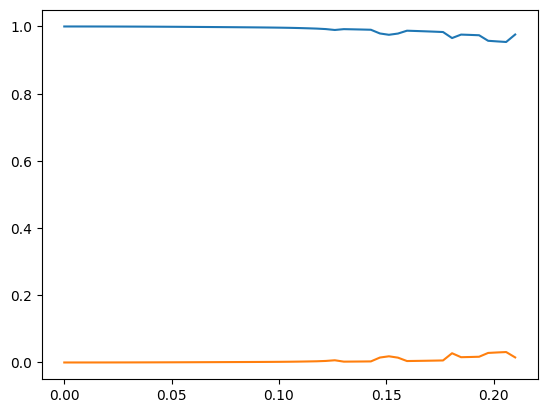

In [26]:
plt.plot(LMBDA, first_sub_wt_p)
plt.plot(LMBDA, second_sub_wt_p)

In [37]:
LMBDA = np.linspace(0,0.21,51)
first_sub_wt_p = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_effect_on_spin_Splitting\\sub_band_wt_with_lmbda_first_v1.npy")

Text(0, 0.5, 'wt in first y subband')

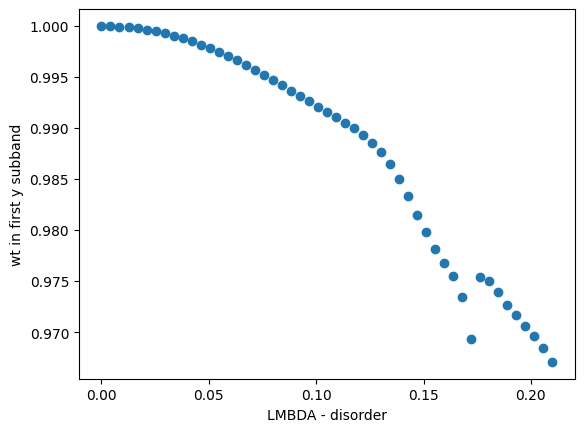

In [38]:

plt.scatter(LMBDA, first_sub_wt_p)
plt.xlabel('LMBDA - disorder')
plt.ylabel('wt in first y subband')

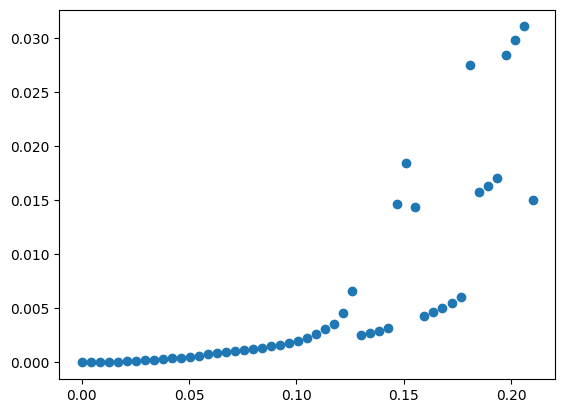

In [29]:

plt.scatter(LMBDA, second_sub_wt_p)

In [39]:
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_effect_on_spin_Splitting\\Ep_no_soc_one_spin_vs_lmbda_0.00_to_0.25_mu_0.80_V1.npy")
#first_sub_wt_p = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_effect_on_spin_Splitting\\sub_band_wt_with_lmbda_first_v1.npy")

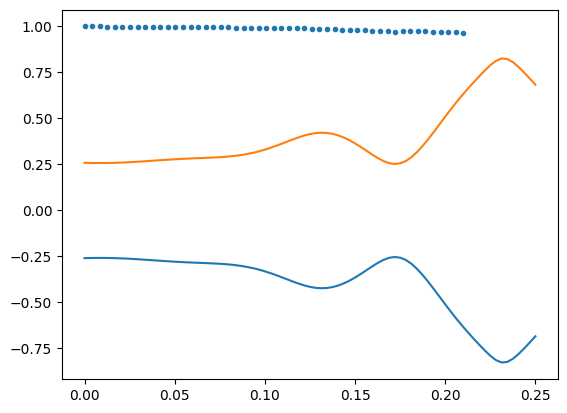

In [40]:
LMBDA = np.linspace(0.0, 0.21, 51)

plt.scatter(LMBDA, first_sub_wt_p, marker=".")

LMBDA = np.linspace(0.0, 0.25, 81)

plt.plot(LMBDA, Ep[:,3:5])